# NB03 - Analisis dan Evaluasi Hasil Simulasi

Notebook ini mengukur perbedaan warna ΔE00 antara setiap pasangan citra asli dan citra hasil simulasi Machado menggunakan rumus standar CIEDE2000, lalu meringkas hasil menurut tipe simulasi dan severity.


In [1]:
%pip install opencv-python-headless numpy pandas matplotlib scikit-image -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Memuat Laporan Simulasi

In [2]:
from __future__ import annotations
import sys, time
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.color import deltaE_ciede2000
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/ tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from machado import simulate_machado_bgr
from utils import find_research_root, sha256_file, write_csv, write_json
RESEARCH_ROOT=find_research_root("notebooks/02/output/simulation_report.csv")
SIMULATION_REPORT_PATH=RESEARCH_ROOT/"notebooks/02/output/simulation_report.csv"
OUTPUT_DIR=RESEARCH_ROOT/"notebooks/03/output"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CVD_FAMILIES=("protan","deutan")
SEVERITIES=(0.25,0.50,0.75,1.00)

simulation_report=pd.read_csv(SIMULATION_REPORT_PATH).sort_values(["cvd_family","severity","source_class","source_file_name"]).reset_index(drop=True)
required={"subset","source_class","source_file_name","input_path","output_path","cvd_family","severity"}
missing=required-set(simulation_report.columns)
if missing: raise ValueError(f"Kolom laporan simulasi tidak lengkap: {sorted(missing)}")
if simulation_report.empty: raise RuntimeError("Laporan simulasi kosong.")
source_count=simulation_report[["subset","source_class","source_file_name"]].drop_duplicates().shape[0]
print(f"Pasangan citra yang dievaluasi: {len(simulation_report)}")

Pasangan citra yang dievaluasi: 4200


## Tahap 2 - Menghitung ΔE00 Setiap Pasangan Citra


In [3]:
def mean_delta_e00(input_bgr: np.ndarray, output_bgr: np.ndarray) -> float:
    first=cv2.cvtColor(input_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    second=cv2.cvtColor(output_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    first[:,:,0]*=100.0/255.0; second[:,:,0]*=100.0/255.0
    first[:,:,1:]-=128.0; second[:,:,1:]-=128.0
    return float(deltaE_ciede2000(first,second).mean())

started = time.perf_counter()
evaluation_rows=[]
for index,row in simulation_report.iterrows():
    original=cv2.imread(row["input_path"],cv2.IMREAD_COLOR)
    simulated=cv2.imread(row["output_path"],cv2.IMREAD_COLOR)
    if original is None or simulated is None or original.shape != simulated.shape: raise ValueError(f"Pasangan citra tidak valid: {row['output_path']}")
    evaluation_rows.append({"subset":row["subset"],"source_class":row["source_class"],"source_file_name":row["source_file_name"],"cvd_family":row["cvd_family"],"severity":row["severity"],"input_path":row["input_path"],"output_path":row["output_path"],"mean_delta_e00":mean_delta_e00(original,simulated)})
    if (index+1)%1000==0 or index+1==len(simulation_report): print(f"{index+1}/{len(simulation_report)} pasangan dievaluasi, {time.perf_counter()-started:.1f} detik")
evaluation=pd.DataFrame(evaluation_rows).sort_values(["cvd_family","severity","source_class","source_file_name"]).reset_index(drop=True)
print(f"Rata-rata ΔE00 keseluruhan: {evaluation['mean_delta_e00'].mean():.4f}")

KeyboardInterrupt: 

In [ ]:
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def read_bgr(path: str) -> np.ndarray:
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Citra tidak dapat dibaca: {path}")
    return image


def calculate_delta_e00_map(
    original_bgr: np.ndarray,
    simulated_bgr: np.ndarray,
) -> np.ndarray:
    original_lab = cv2.cvtColor(
        original_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    simulated_lab = cv2.cvtColor(
        simulated_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    original_lab[:, :, 0] *= 100.0 / 255.0
    simulated_lab[:, :, 0] *= 100.0 / 255.0

    original_lab[:, :, 1:] -= 128.0
    simulated_lab[:, :, 1:] -= 128.0

    return deltaE_ciede2000(original_lab, simulated_lab)

In [ ]:
def select_examples(group: pd.DataFrame) -> pd.DataFrame:
    cvd_family, severity = group.name

    ordered = group.sort_values(
        ["mean_delta_e00", "source_class", "source_file_name"]
    ).reset_index(drop=True)

    median_value = ordered["mean_delta_e00"].median()

    median_index = (
        (ordered["mean_delta_e00"] - median_value)
        .abs()
        .sort_values(kind="stable")
        .index[0]
    )

    examples = pd.concat(
        [
            ordered.iloc[[0]].assign(example_type="terendah"),
            ordered.loc[[median_index]].assign(
                example_type="mendekati_median"
            ),
            ordered.iloc[[-1]].assign(example_type="tertinggi"),
        ],
        ignore_index=True,
    )

    examples["cvd_family"] = cvd_family
    examples["severity"] = severity

    return examples.drop_duplicates(
        subset=[
            "source_class",
            "source_file_name",
            "cvd_family",
            "severity",
        ]
    )


representative_cases = (
    evaluation.groupby(
        ["cvd_family", "severity"],
        group_keys=False,
    )
    .apply(select_examples, include_groups=False)
    .reset_index(drop=True)
)

write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    ["cvd_family", "severity", "example_type"],
)

representative_cases[
    [
        "cvd_family",
        "severity",
        "example_type",
        "source_class",
        "source_file_name",
        "mean_delta_e00",
    ]
]

,cvd_family,severity,example_type,source_class,source_file_name,mean_delta_e00
0,deutan,0.25,terendah,006banana,113.png,0.453067
1,deutan,0.25,mendekati_median,015pomelo,81.png,2.587237
2,deutan,0.25,tertinggi,002orange,204.png,9.924043
3,deutan,0.50,terendah,006banana,113.png,0.715256
4,deutan,0.50,mendekati_median,015pomelo,74.png,4.306539
5,deutan,0.50,tertinggi,002orange,204.png,18.116657
6,deutan,0.75,terendah,006banana,113.png,0.925051
7,deutan,0.75,mendekati_median,015pomelo,74.png,5.514713
8,deutan,0.75,tertinggi,001apple,87.png,25.832016
9,deutan,1.00,terendah,006banana,113.png,1.253533


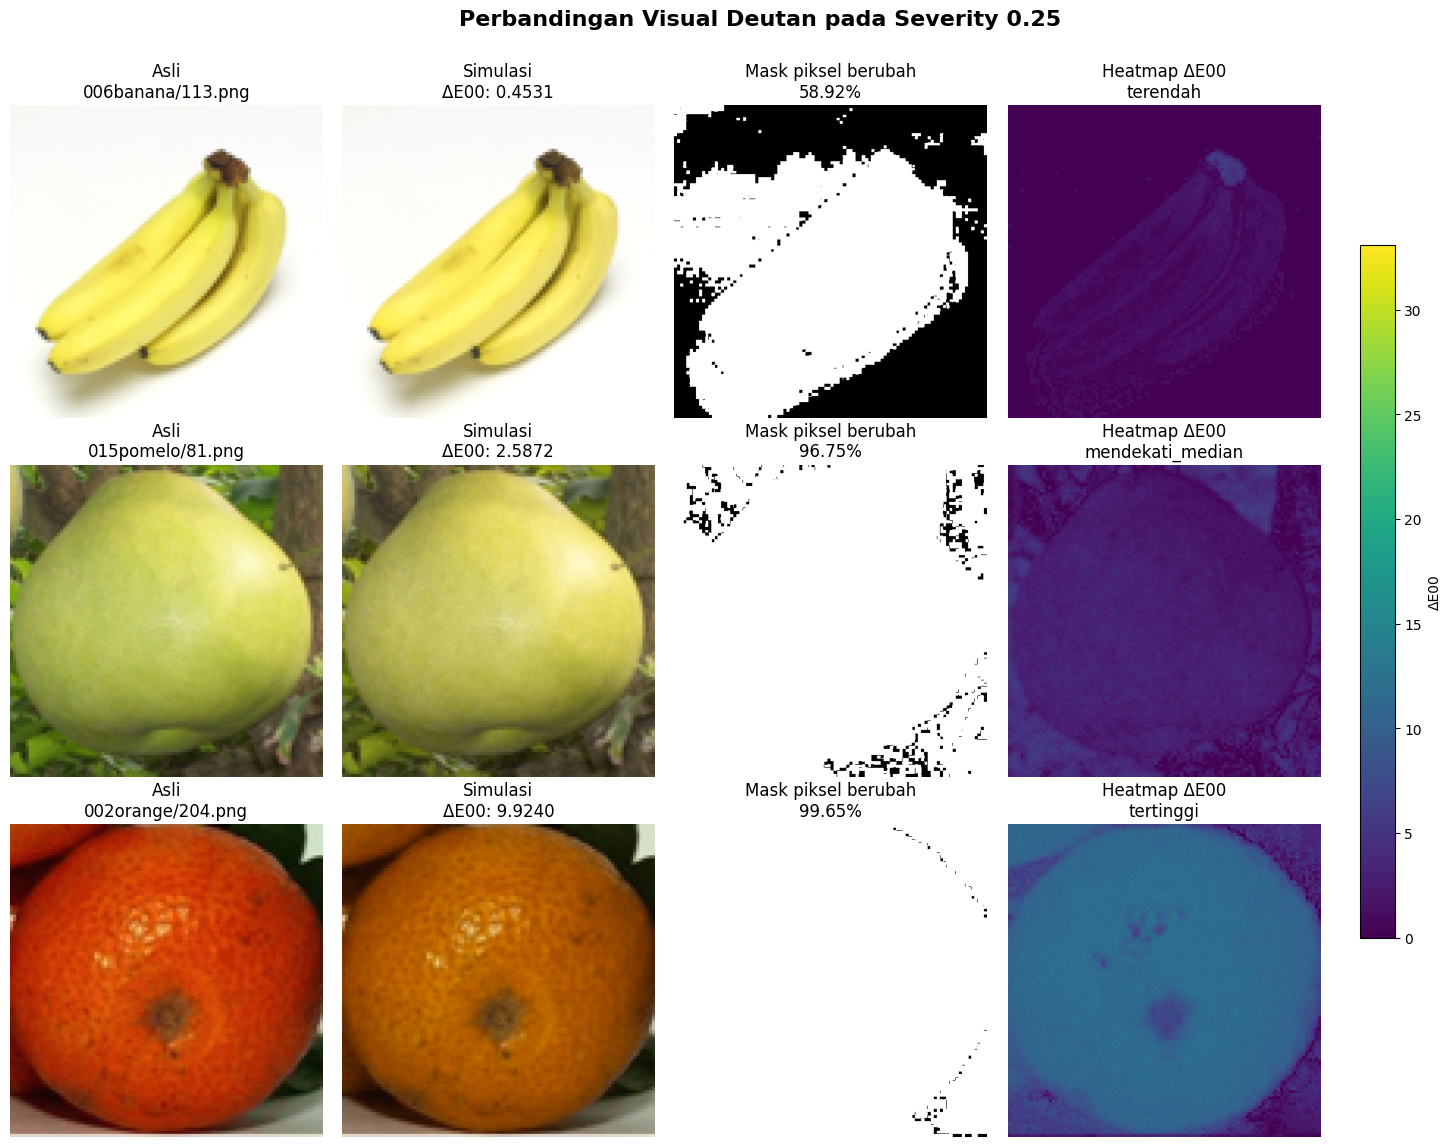

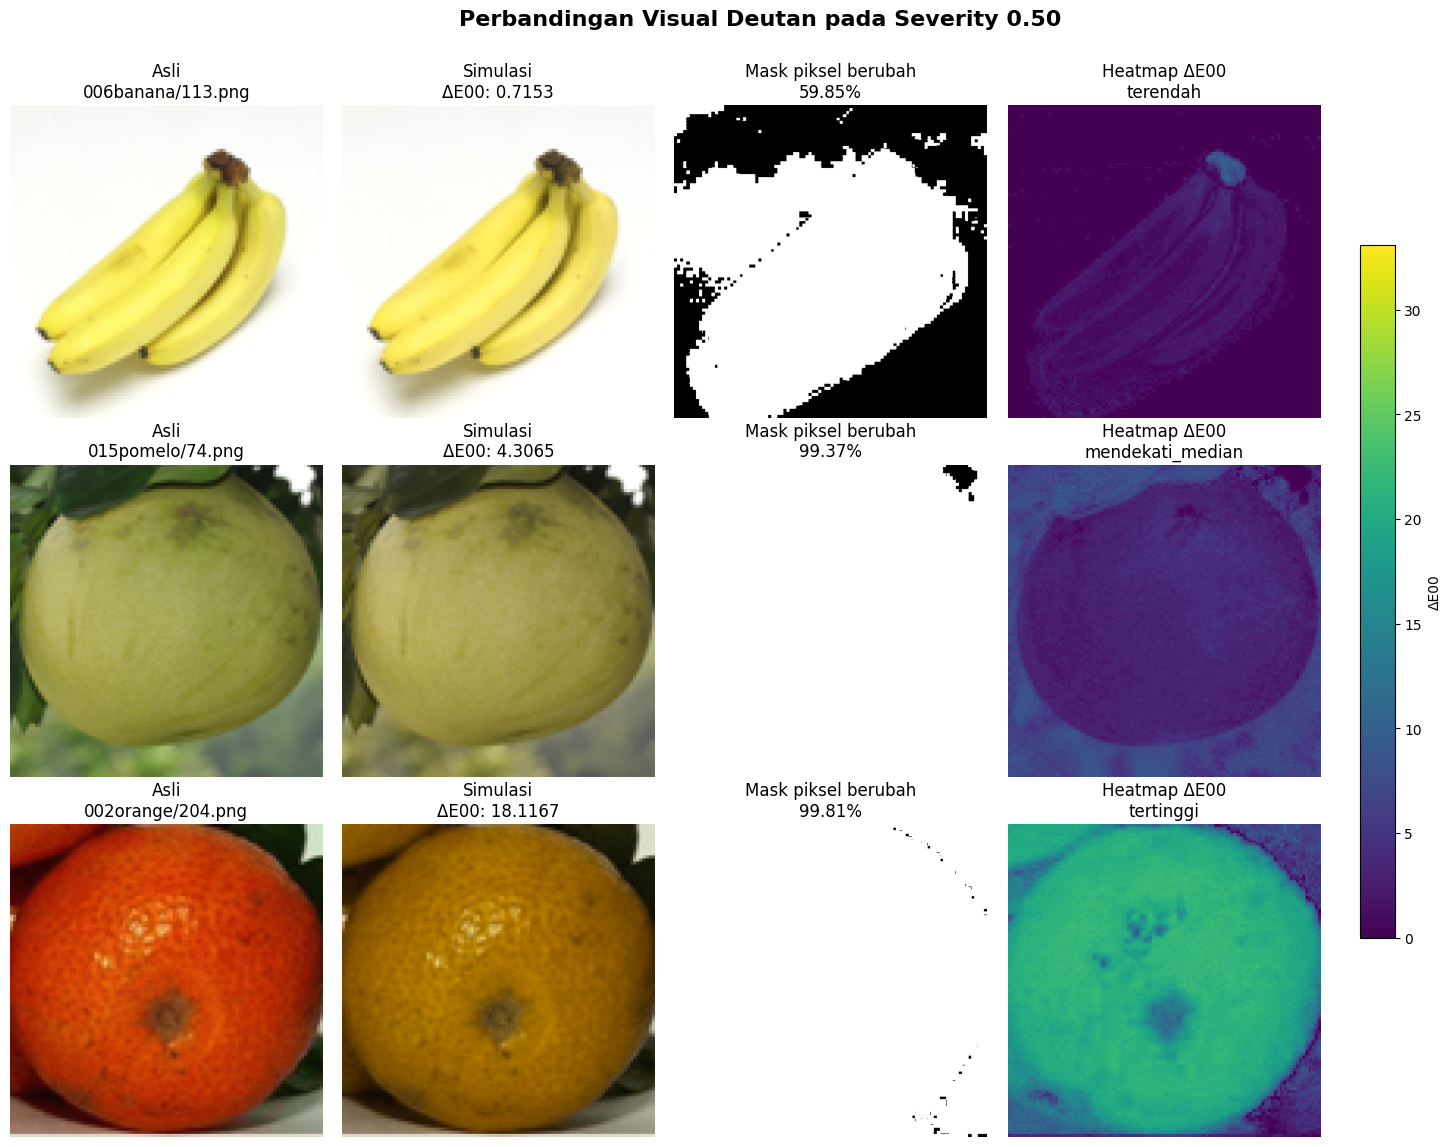

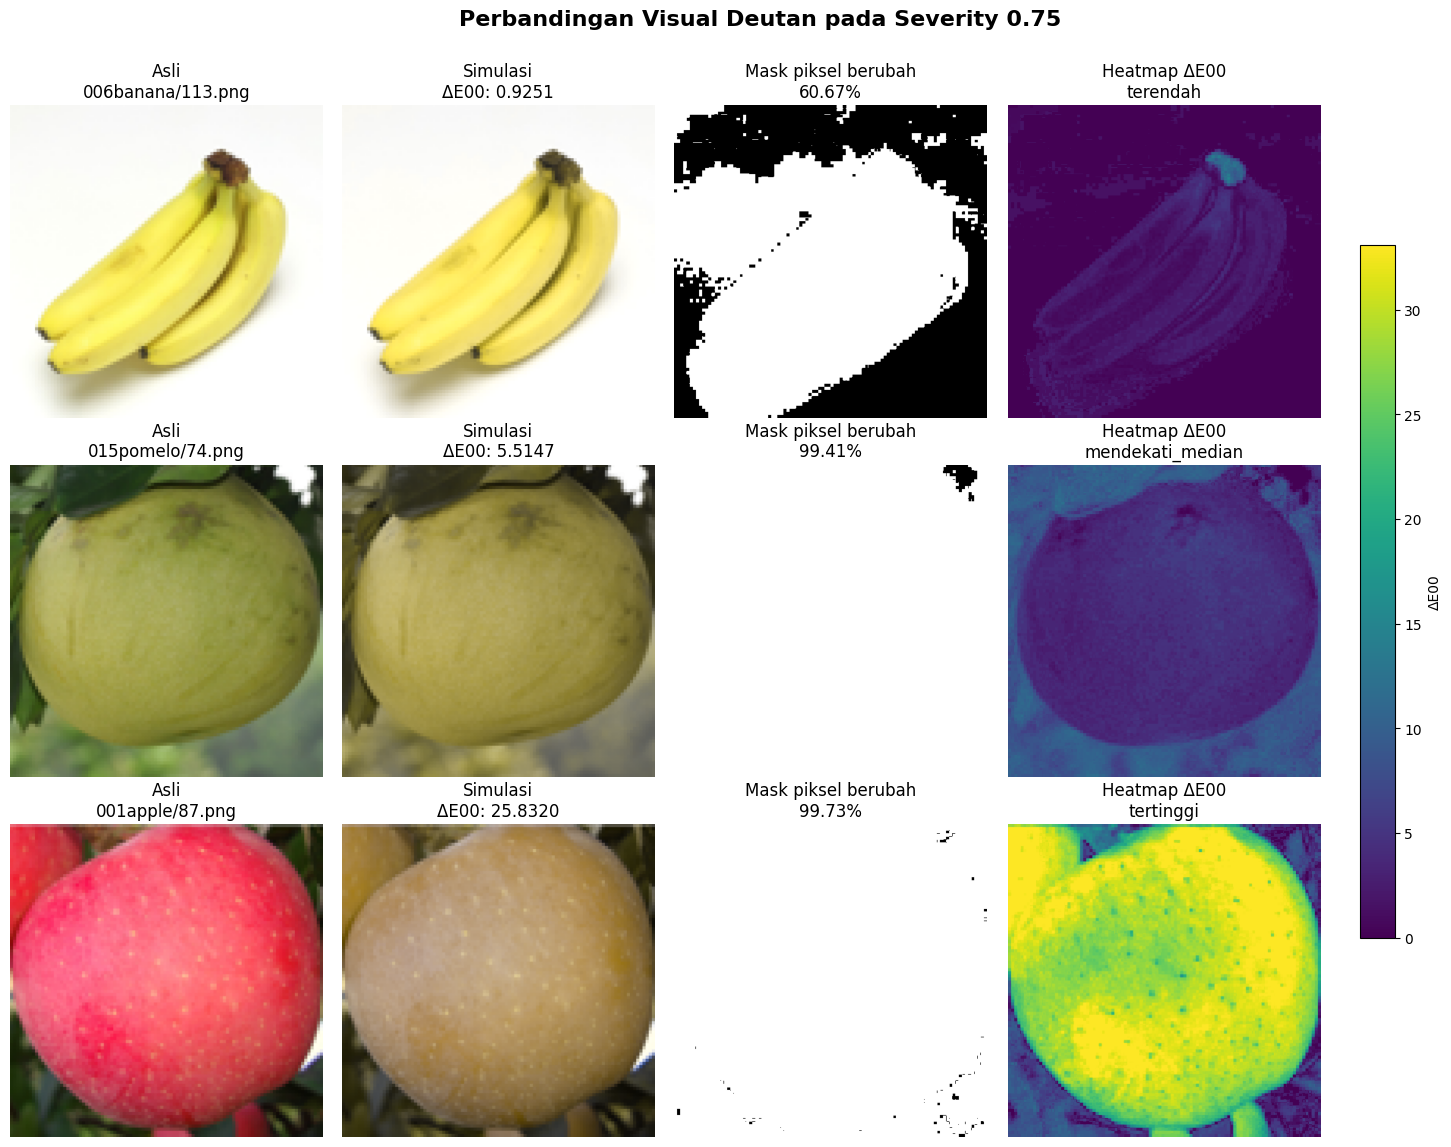

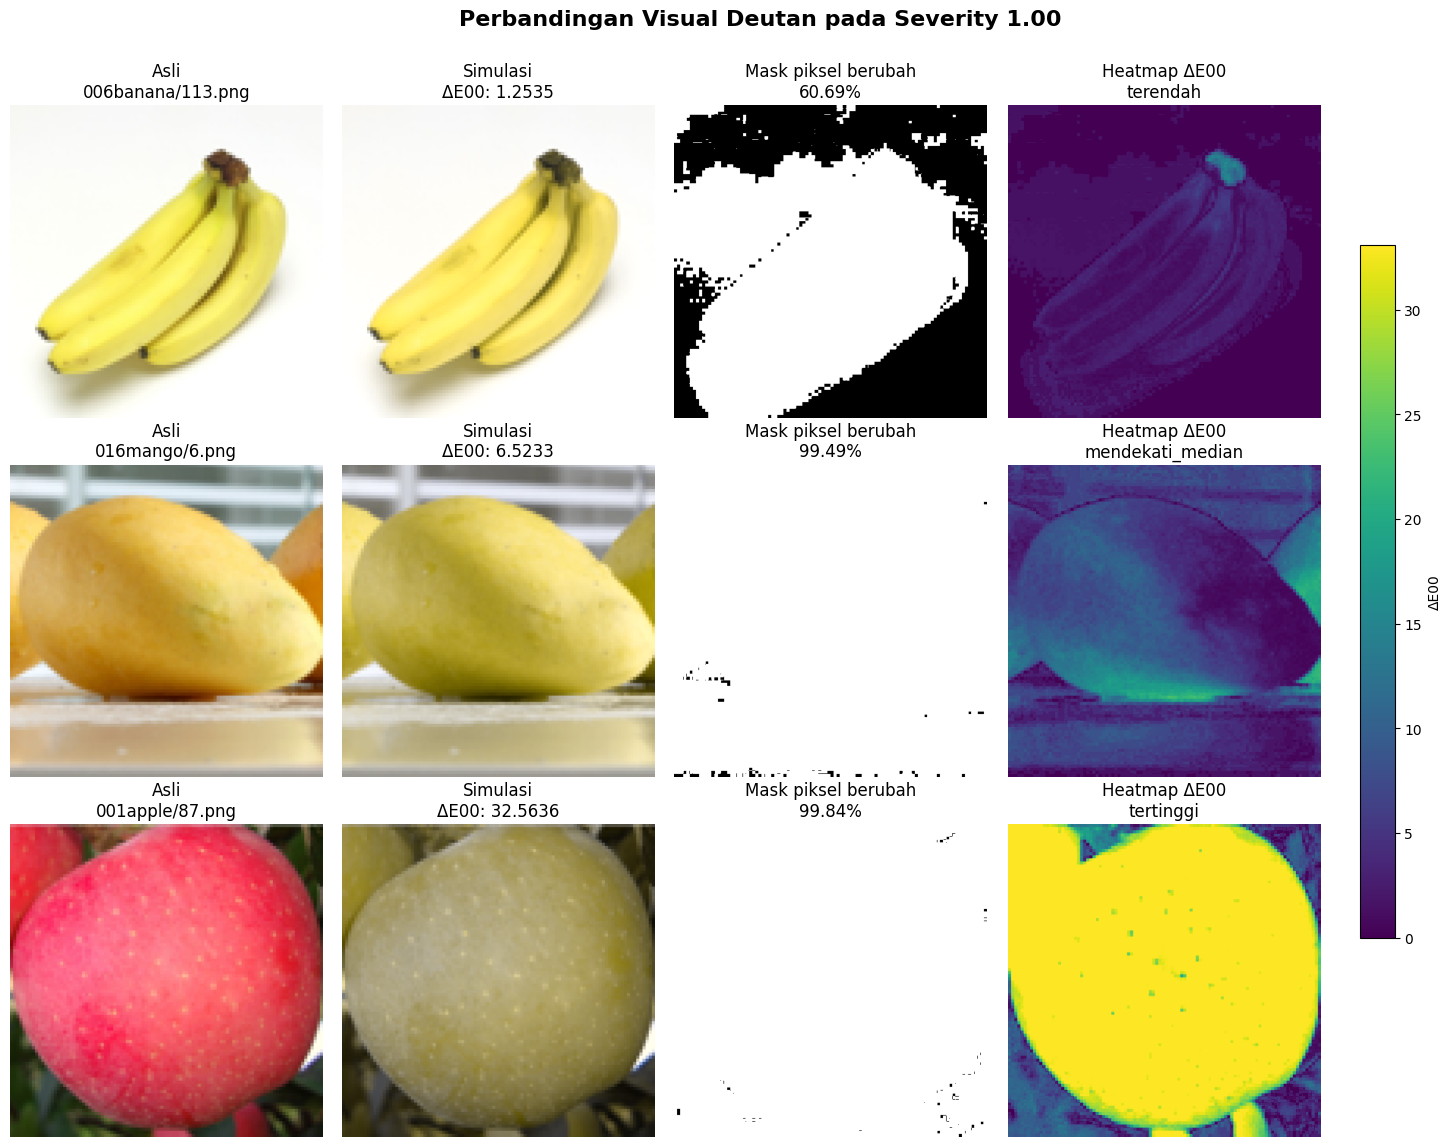

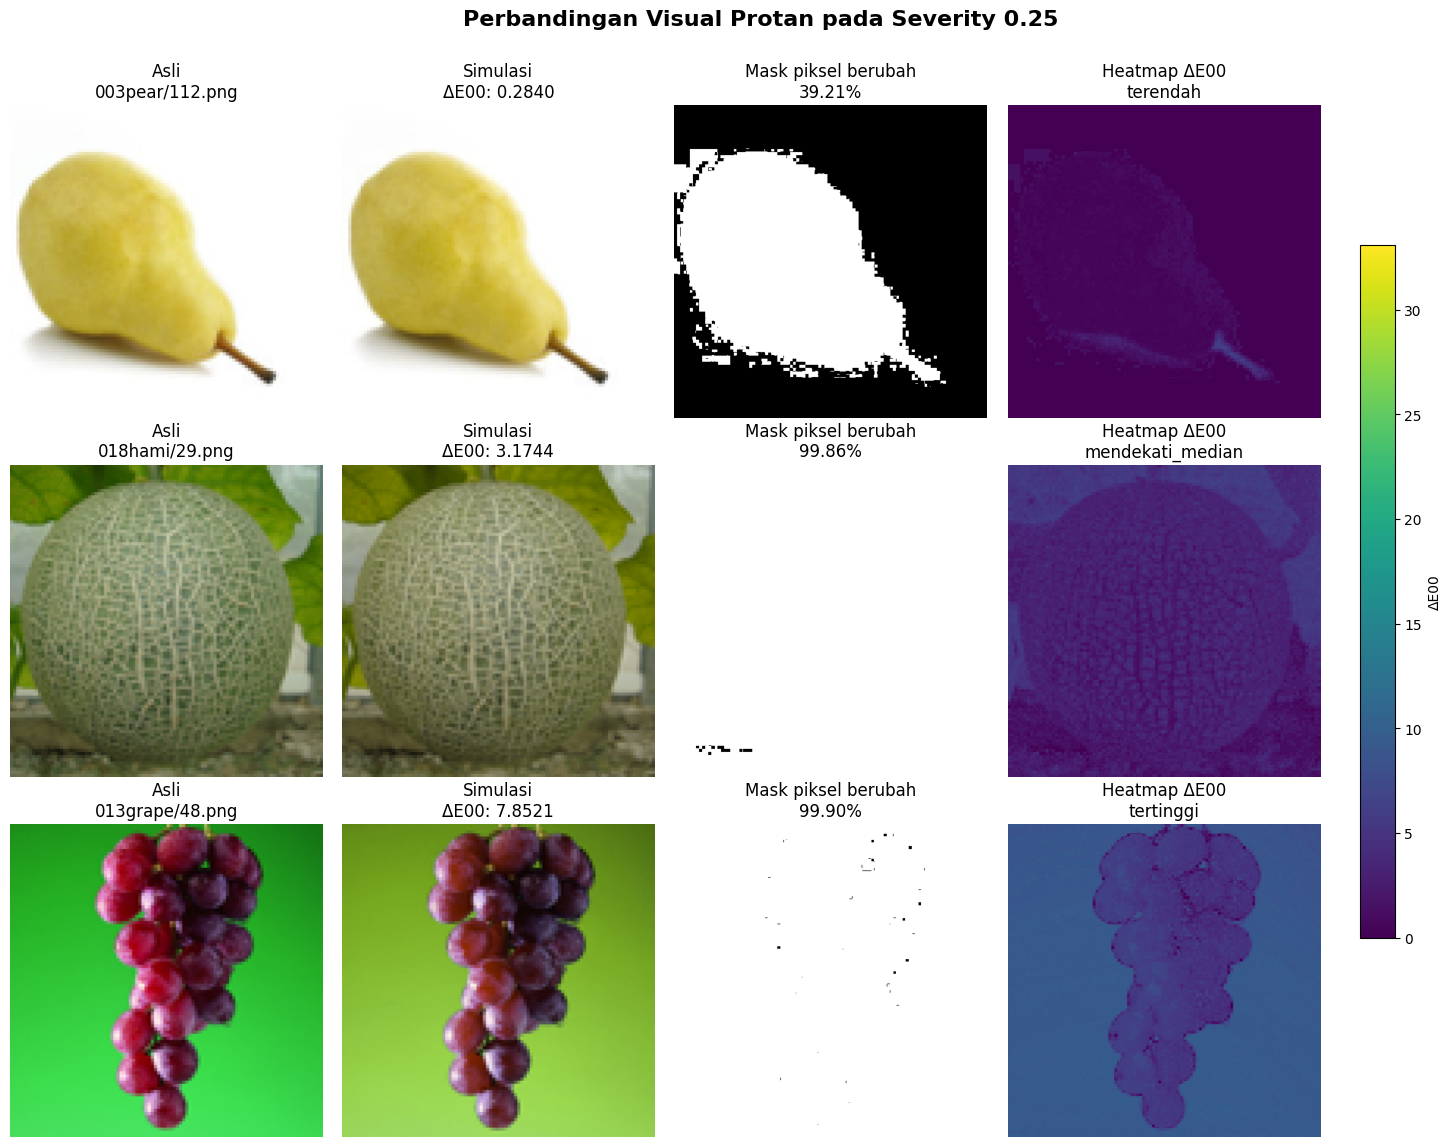

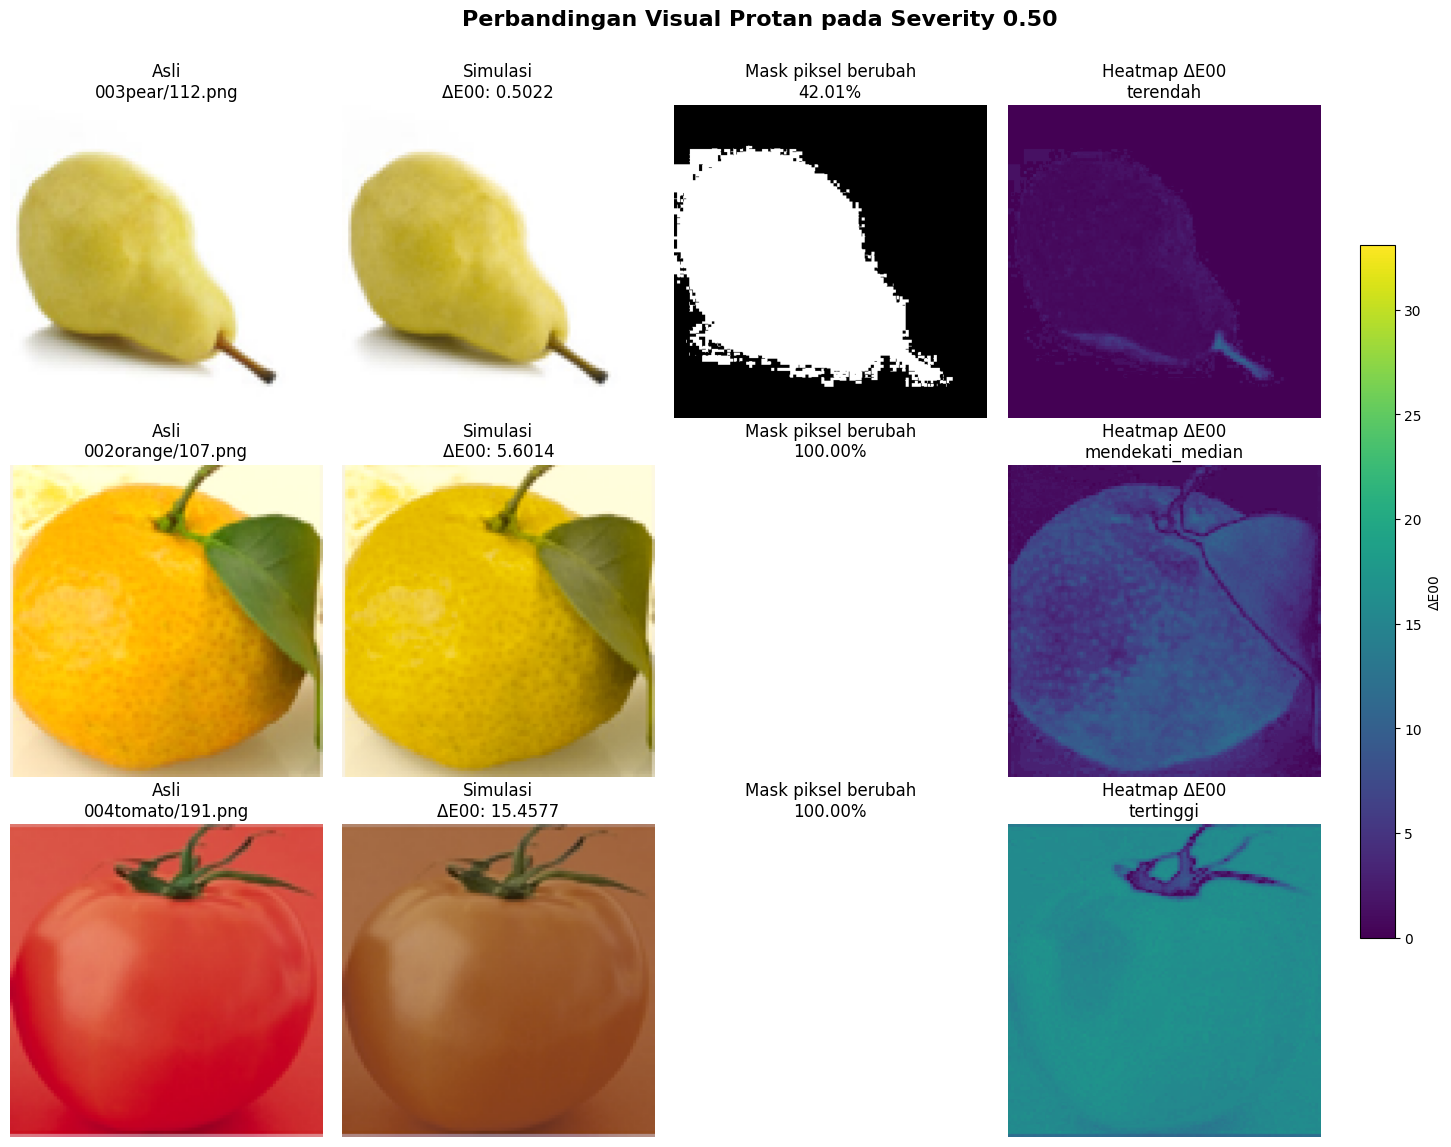

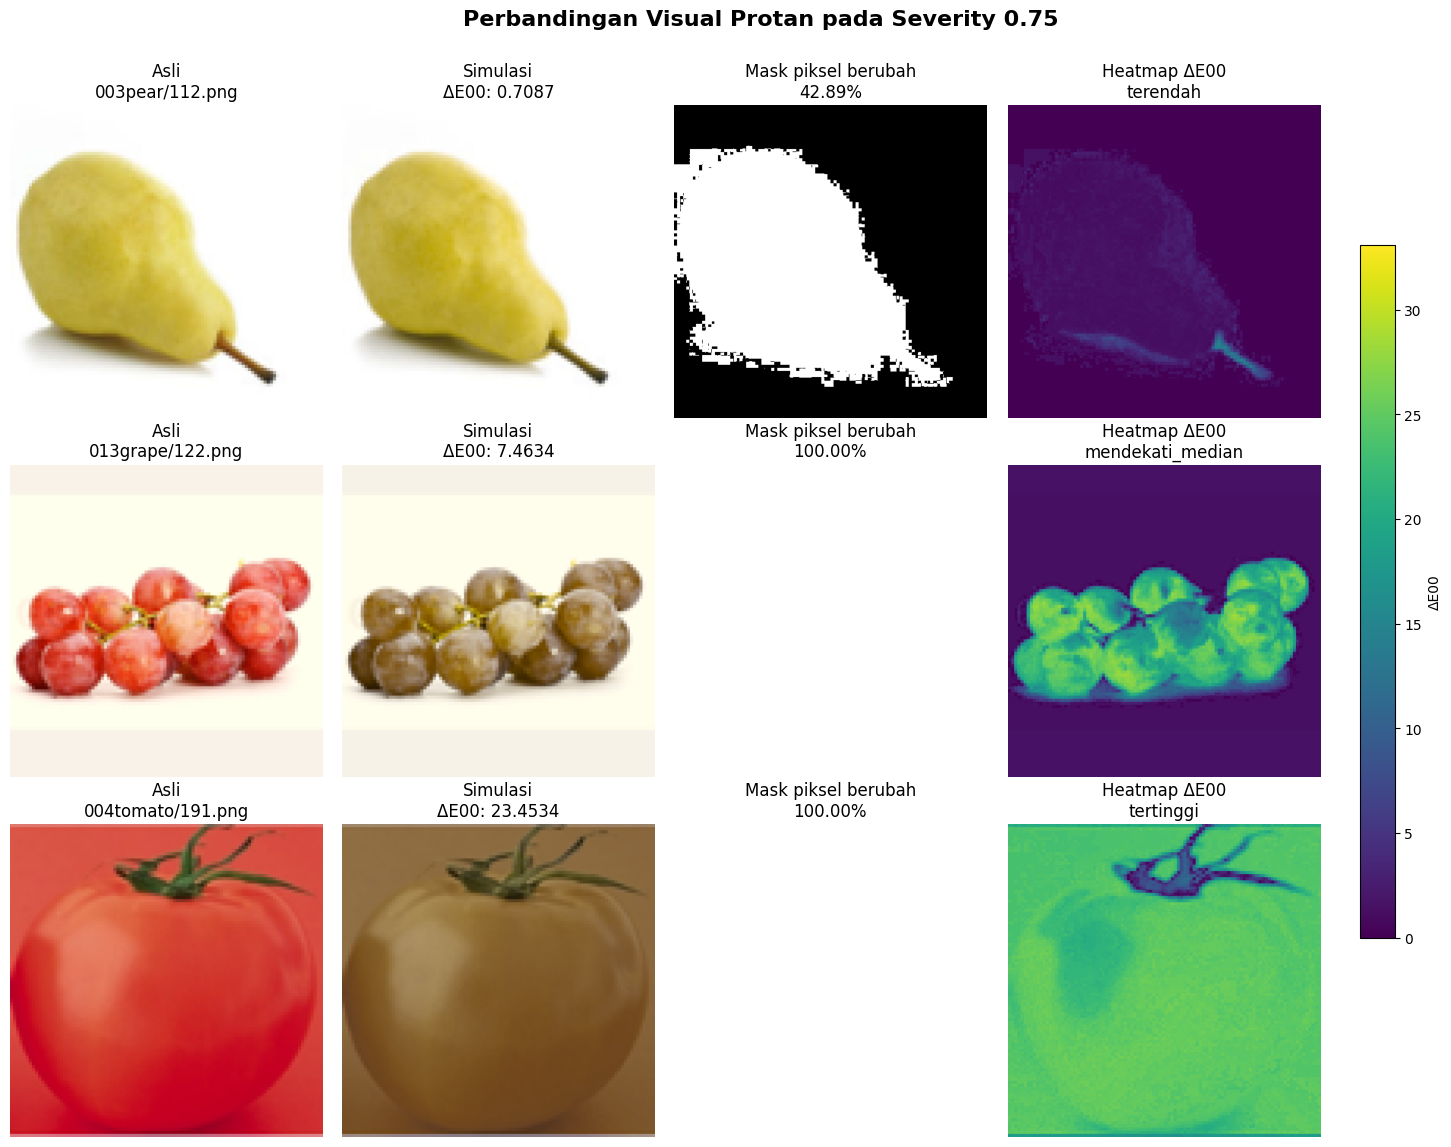

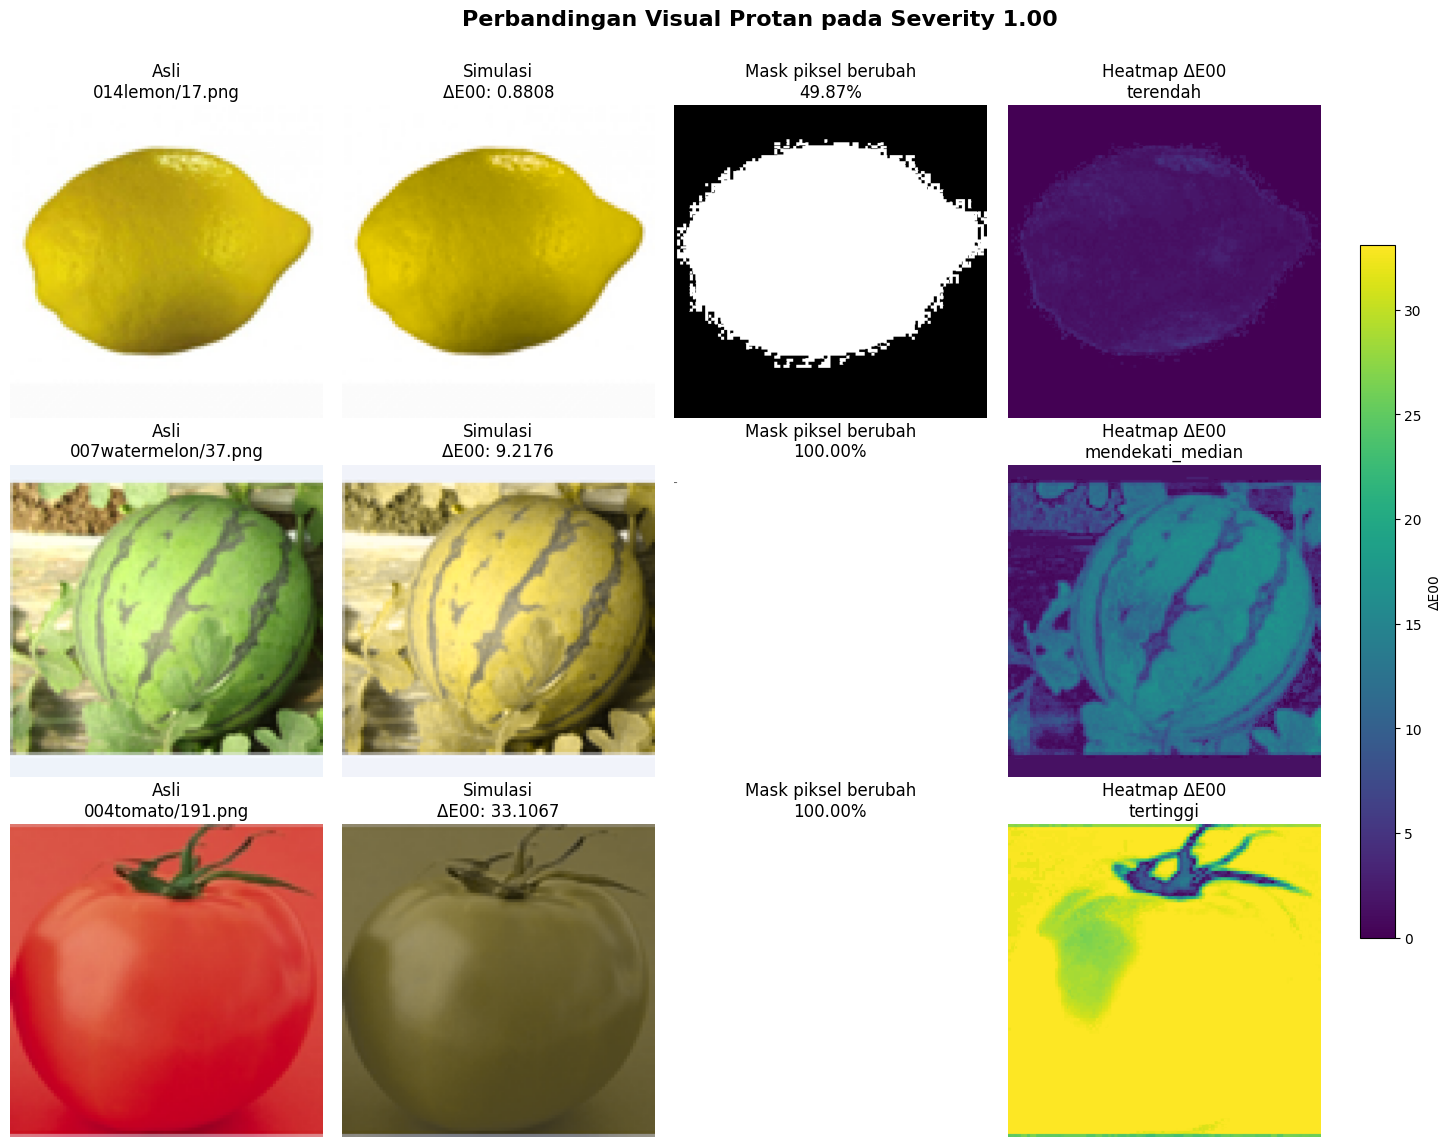

In [ ]:
delta_e00_max = float(evaluation["mean_delta_e00"].max())

example_order = {
    "terendah": 0,
    "mendekati_median": 1,
    "tertinggi": 2,
}


def create_visual_panel(cases: pd.DataFrame) -> None:
    ordered_cases = cases.sort_values(
        "example_type",
        key=lambda values: values.map(example_order),
    )

    figure, axes = plt.subplots(3, 4, figsize=(16, 12))

    for row_index, (_, item) in enumerate(ordered_cases.iterrows()):
        original_bgr = read_bgr(item["input_path"])
        simulated_bgr = read_bgr(item["output_path"])

        delta_e00_map = calculate_delta_e00_map(
            original_bgr,
            simulated_bgr,
        )

        changed_mask = np.any(
            original_bgr != simulated_bgr,
            axis=2,
        )

        axes[row_index, 0].imshow(
            cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 0].set_title(
            f"Asli\n{item['source_class']}/{item['source_file_name']}"
        )

        axes[row_index, 1].imshow(
            cv2.cvtColor(simulated_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 1].set_title(
            f"Simulasi\nΔE00: {item['mean_delta_e00']:.4f}"
        )

        axes[row_index, 2].imshow(
            changed_mask,
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row_index, 2].set_title(
            f"Mask piksel berubah\n{changed_mask.mean():.2%}"
        )

        heatmap = axes[row_index, 3].imshow(
            delta_e00_map,
            cmap="viridis",
            vmin=0,
            vmax=delta_e00_max,
        )
        axes[row_index, 3].set_title(
            f"Heatmap ΔE00\n{item['example_type']}"
        )

        for axis in axes[row_index]:
            axis.axis("off")

    figure.colorbar(
        heatmap,
        ax=axes[:, 3],
        shrink=0.75,
        label="ΔE00",
    )

    cvd_family = ordered_cases.iloc[0]["cvd_family"]
    severity = ordered_cases.iloc[0]["severity"]

    figure.suptitle(
        f"Perbandingan Visual {cvd_family.title()} "
        f"pada Severity {severity:.2f}",
        fontsize=16,
        fontweight="bold",
    )

    figure.subplots_adjust(
        top=0.90,
        bottom=0.04,
        left=0.03,
        right=0.85,
        hspace=0.15,
        wspace=0.05,
    )

    output_path = (
        FIGURE_DIR
        / f"visual_{cvd_family}_severity_{int(severity * 100):03d}.png"
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)


for _, cases in representative_cases.groupby(
    ["cvd_family", "severity"],
):
    create_visual_panel(cases)

## Tahap 3 - Agregasi, Visualisasi, dan Ekspor Hasil


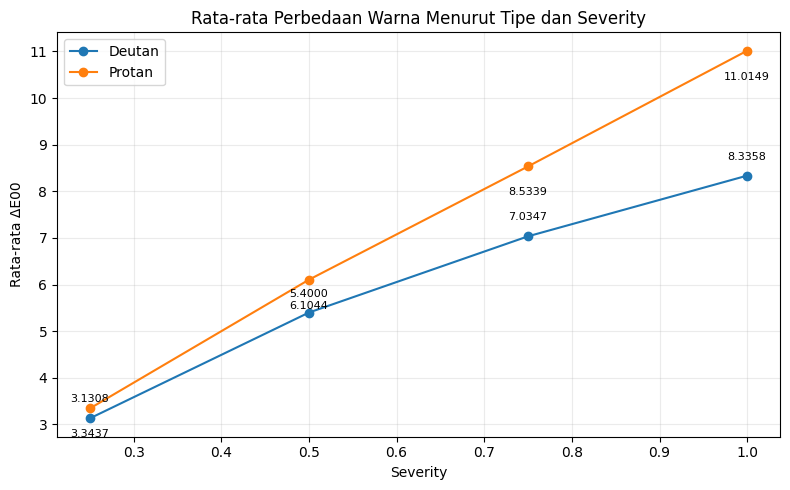

,cvd_family,severity,image_count,mean_delta_e00,median_delta_e00,minimum_delta_e00,maximum_delta_e00
0,deutan,0.25,525,3.130794,2.587237,0.453067,9.924043
1,deutan,0.50,525,5.400010,4.306539,0.715256,18.116657
2,deutan,0.75,525,7.034714,5.514713,0.925051,25.832016
3,deutan,1.00,525,8.335822,6.523270,1.253533,32.563604
4,protan,0.25,1088,3.343694,3.166843,0.284018,7.852069
5,protan,0.50,1088,6.104376,5.593446,0.502202,15.457719
6,protan,0.75,1088,8.533896,7.452867,0.708692,23.453378
7,protan,1.00,1088,11.014905,9.210780,0.880818,33.106662


In [ ]:
group_summary=evaluation.groupby(["cvd_family","severity"],as_index=False).agg(image_count=("mean_delta_e00","size"),mean_delta_e00=("mean_delta_e00","mean"),median_delta_e00=("mean_delta_e00","median"),minimum_delta_e00=("mean_delta_e00","min"),maximum_delta_e00=("mean_delta_e00","max"))
write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    [
        "cvd_family",
        "severity",
        "example_type",
    ],
)

write_csv(
    group_summary,
    OUTPUT_DIR / "evaluation_group_summary.csv",
    ["cvd_family", "severity"],
)

plt.figure(figsize=(8, 5))

for family, group in group_summary.groupby("cvd_family"):
    group = group.sort_values("severity")

    line, = plt.plot(
        group["severity"],
        group["mean_delta_e00"],
        marker="o",
        label=family.title()
    )

    # Posisi label berdasarkan tipe CVD
    if family.lower() == "protan":
        offset = (0, -15)  # Di bawah titik
        va = "top"
    elif family.lower() == "deutan":
        offset = (0, 10)   # Di atas titik
        va = "bottom"
    else:
        offset = (0, 10)
        va = "bottom"

    # Tampilkan nilai pada setiap titik kurva
    for x, y in zip(group["severity"], group["mean_delta_e00"]):
        plt.annotate(
            f"{y:.4f}",
            (x, y),
            textcoords="offset points",
            xytext=offset,
            ha="center",
            va=va,
            fontsize=8
        )

plt.xlabel("Severity")
plt.ylabel("Rata-rata ΔE00")
plt.title("Rata-rata Perbedaan Warna Menurut Tipe dan Severity")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "mean_delta_e00_by_condition.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

group_summary
